# PathSnap — Model Training, Comparison & Route Reconstruction

This notebook is designed for **Google Colab**. Upload the original PathSnap ZIP when prompted. It performs dataset inspection, GPS/road-network preprocessing, candidate generation, feature engineering, group-aware model comparison, GPU-aware XGBoost (CUDA when available, CPU fallback otherwise), Bayesian-style hyperparameter search (Optuna when available), and a basic HMM/Viterbi route decoder.

**Important methodological note:** the supplied `.route` file is a sequence of reference `arc_id` values, not a GPS-row-aligned label file. This notebook creates observation-level reference labels by finding the closest supplied route segment geometrically for each GPS observation. This is an explicit approximation and is reported as such. Inspect the generated diagnostics before treating the metrics as final ground truth.

The notebook never reads evaluator-testing data. The uploaded package currently expected by this project contains `train/` and `student_test/`; if an evaluator partition is later provided, it is deliberately ignored by this training notebook.

This version adds auditable GPS cleaning, actual cleaning plots, complete model comparison diagnostics, measured boosting histories, and Bayesian before/after plots. XGBoost attempts CUDA on Colab T4 and explicitly reports CPU fallback if the runtime does not support it.

## 1. Install dependencies and select runtime

In Colab choose **Runtime → Change runtime type → T4 GPU** (or another available GPU). Tree models from scikit-learn are CPU-based; XGBoost will use CUDA when the runtime and installed XGBoost build support it, and will automatically fall back to CPU.

In [1]:
!pip -q install numpy pandas scipy scikit-learn matplotlib seaborn xgboost lightgbm optuna folium joblib
import os, sys, re, zipfile, time, json, math, random, warnings, shutil
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             log_loss, confusion_matrix, classification_report)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
import lightgbm as lgb
import joblib
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("Python:", sys.version)
try:
    import torch
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("PyTorch GPU check unavailable:", e)


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
CUDA available: False


## 2. Upload the dataset ZIP

Run this cell and select the ZIP containing the `train/` and `student_test/` folders. You can also mount Google Drive and set `ZIP_PATH` manually if the file is already there.

In [2]:
from google.colab import files
uploaded = files.upload()  # Select the original PathSnap ZIP
zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_candidates:
    raise ValueError("No ZIP file was uploaded. Re-run this cell and select the PathSnap dataset ZIP.")
ZIP_PATH = zip_candidates[0]
print("Using dataset:", ZIP_PATH)


Saving Student folder.zip to Student folder.zip
Using dataset: Student folder.zip


## 3. Extract and discover trips

The reader handles an optional enclosing folder such as `Student folder/`. It identifies trip directories from their `.track`, `.nodes`, `.arcs`, and `.route` files rather than relying on fixed folder names.

In [3]:
DATA_ROOT = Path("/content/pathsnap_data")
if DATA_ROOT.exists(): shutil.rmtree(DATA_ROOT)
DATA_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as zf:
    bad = zf.testzip()
    if bad: raise RuntimeError(f"Corrupt ZIP member: {bad}")
    zf.extractall(DATA_ROOT)

def discover_trips(root):
    trips = {}
    for track in Path(root).rglob("*.track"):
        d = track.parent
        tid = d.name
        files = {p.suffix.lstrip("."): p for p in d.iterdir() if p.is_file()}
        if all(k in files for k in ["track", "nodes", "arcs", "route"]):
            # partition is the directory immediately above trip folder
            partition = d.parent.name.lower()
            trips[(partition, tid)] = files
    return trips

TRIPS = discover_trips(DATA_ROOT)
partition_counts = Counter(p for p, _ in TRIPS)
print("Trips discovered:", len(TRIPS))
print("Partitions:", dict(partition_counts))
assert "train" in partition_counts, "Could not find a train/ partition. Inspect the extracted folder."
assert "student_test" in partition_counts, "Could not find student_test/; check the ZIP structure."

Trips discovered: 90
Partitions: {'student_test': 10, 'train': 80}


## 4. Read raw files and create a dataset inventory

File formats are whitespace-separated and headerless:
- `.track`: longitude, latitude, timestamp (seconds)
- `.nodes`: longitude, latitude; row index is node ID
- `.arcs`: from-node ID, to-node ID; row index is arc ID
- `.route`: chronological reference arc IDs

No assumption is made that a GPS row index equals a road-network row index.

In [4]:
def load_trip(files):
    track = np.loadtxt(files["track"], dtype=float, ndmin=2)
    nodes = np.loadtxt(files["nodes"], dtype=float, ndmin=2)
    arcs = np.loadtxt(files["arcs"], dtype=np.int64, ndmin=2)
    route = np.loadtxt(files["route"], dtype=np.int64, ndmin=1).reshape(-1)
    if track.shape[1] < 3 or nodes.shape[1] < 2 or arcs.shape[1] < 2:
        raise ValueError("Unexpected column count")
    track = track[:, :3]; nodes = nodes[:, :2]; arcs = arcs[:, :2]
    valid_arcs = ((arcs[:,0] >= 0) & (arcs[:,0] < len(nodes)) &
                  (arcs[:,1] >= 0) & (arcs[:,1] < len(nodes)))
    if not np.all(valid_arcs):
        raise ValueError(f"Invalid arc endpoint(s): {int((~valid_arcs).sum())}; refusing to renumber arc IDs.")
    if np.any((route < 0) | (route >= len(arcs))):
        raise ValueError("Reference .route contains arc IDs outside the .arcs file.")
    return track, nodes, arcs, route

inventory = []
for (part, tid), fs in sorted(TRIPS.items()):
    try:
        tr, no, ar, ro = load_trip(fs)
        inventory.append({"partition":part, "trip_id":tid, "gps_rows":len(tr),
                          "nodes":len(no), "arcs":len(ar), "route_arcs":len(ro),
                          "track_bytes":fs["track"].stat().st_size,
                          "route_bytes":fs["route"].stat().st_size,
                          "valid_gps_rows":int(np.isfinite(tr).all(axis=1).sum()),
                          "route_ids_in_range":int(((ro>=0)&(ro<len(ar))).sum())})
    except Exception as e:
        inventory.append({"partition":part, "trip_id":tid, "error":str(e)})
inventory_df = pd.DataFrame(inventory)
display(inventory_df.head(15))
display(inventory_df.groupby("partition")[["gps_rows","nodes","arcs","route_arcs"]].agg(["count","mean","min","max"]))

,partition,trip_id,gps_rows,nodes,arcs,route_arcs,track_bytes,route_bytes,valid_gps_rows,route_ids_in_range
0,student_test,00000000,2503,8542,18196,179,81492,881,2503,179
1,student_test,00000007,1354,2061,4369,123,43575,486,1354,123
2,student_test,00000009,1049,6745,13106,429,33513,2217,1049,429
3,student_test,00000040,2995,12945,27026,309,97728,1506,2995,309
4,student_test,00000052,262,1770,3577,95,8278,474,262,95
5,student_test,00000056,3958,14759,27631,1323,133479,7628,3958,1323
6,student_test,00000065,768,6448,13184,145,24512,701,768,145
7,student_test,00000076,1486,26635,56027,374,48392,2098,1486,374
8,student_test,00000077,3911,4424,9622,268,127956,1258,3911,268
9,student_test,00000091,874,6360,12303,232,26986,1095,874,232


gps_rows                        nodes                            \
                count       mean  min    max count        mean   min     max   
partition                                                                      
student_test       10  1916.0000  262   3958    10   9068.9000  1770   26635   
train              80  2605.2125  361  19313    80  24168.5625   299  155003   

              arcs                        route_arcs                   
             count     mean   min     max      count   mean min   max  
partition                                                              
student_test    10  18504.1  3577   56027         10  347.7  95  1323  
train           80  48461.3   649  307392         80  391.7  59  2266

## 5. Dataset quality checks and exploratory plots

We inspect timestamp order/gaps, coordinate ranges, missing values, network size, and route validity. The coordinates in the supplied example are longitude around 54–55 and latitude around 56; calculations below use a local metre-based projection around each trip's mean latitude/longitude, rather than Euclidean degrees.

,partition,trip_id,missing,non_increasing_time,gap_gt_2s,max_gap_s,route_invalid_ids,isolated_nodes_est,lon_min,lon_max,lat_min,lat_max
0,student_test,00000007,0,0,0,1.0,0,0,77.122052,77.271115,43.388762,43.496413
1,student_test,00000009,0,0,0,2.0,0,0,13.631991,13.706620,42.645529,42.662443
2,student_test,00000091,0,0,0,1.0,0,0,2.411206,2.443703,47.053146,47.099623
3,student_test,00000077,0,0,0,1.0,0,0,50.788938,50.841452,61.639754,61.699590
4,student_test,00000056,0,0,2,3.0,0,0,-93.424337,-93.348525,44.836021,44.873400
5,student_test,00000052,0,0,0,2.0,0,0,35.858383,35.896431,56.795125,56.827472
6,student_test,00000065,0,0,8,210.0,0,0,49.263178,49.329869,53.512628,53.538940
7,student_test,00000076,0,0,128,32.0,0,0,43.961393,44.033831,56.240407,56.328848
8,student_test,00000000,0,0,0,2.0,0,0,54.248491,54.963519,56.080560,56.254566
9,student_test,00000040,0,0,0,1.0,0,0,61.069448,61.292663,55.175283,55.416496


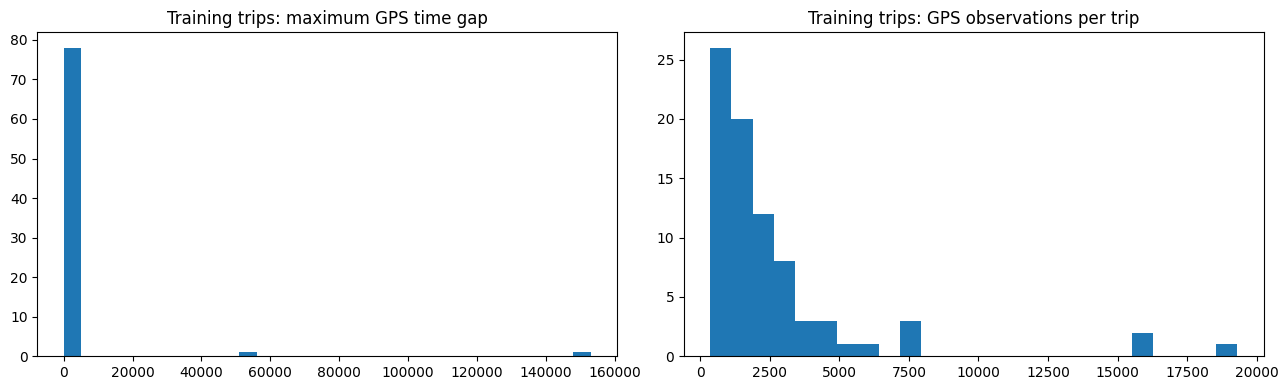

In [5]:
def haversine_m(lon1, lat1, lon2, lat2):
    R=6371000.0
    p1=np.radians(lat1); p2=np.radians(lat2)
    dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arcsin(np.sqrt(np.clip(a,0,1)))

quality=[]
for (part,tid),fs in TRIPS.items():
    try:
        tr,no,ar,ro=load_trip(fs)
        t=tr[:,2]; dt=np.diff(t)
        quality.append({"partition":part,"trip_id":tid,"missing":int((~np.isfinite(tr)).any(axis=1).sum()),
                        "non_increasing_time":int((dt<=0).sum()),"gap_gt_2s":int((dt>2).sum()),
                        "max_gap_s":float(np.nanmax(dt)) if len(dt) else 0,
                        "route_invalid_ids":int(((ro<0)|(ro>=len(ar))).sum()),
                        "isolated_nodes_est":int(len(set(range(len(no)))-set(ar.ravel()))),
                        "lon_min":float(np.nanmin(tr[:,0])),"lon_max":float(np.nanmax(tr[:,0])),
                        "lat_min":float(np.nanmin(tr[:,1])),"lat_max":float(np.nanmax(tr[:,1]))})
    except Exception as e:
        quality.append({"partition":part,"trip_id":tid,"error":str(e)})
quality_df=pd.DataFrame(quality)
display(quality_df.head(12))
fig,ax=plt.subplots(1,2,figsize=(13,4))
train_gaps=quality_df.loc[quality_df.partition=="train","max_gap_s"].dropna()
train_rows=inventory_df.loc[inventory_df.partition=="train","gps_rows"].dropna()
ax[0].hist(train_gaps,bins=30)
ax[0].set_title("Training trips: maximum GPS time gap")
ax[1].hist(train_rows,bins=25)
ax[1].set_title("Training trips: GPS observations per trip")
plt.tight_layout(); plt.show()


## 5A. Auditable GPS data cleaning

This stage preserves the original ZIP and creates a cleaned in-memory GPS trajectory for modelling.
It applies conservative corrections only:
- Remove rows with non-finite values or impossible longitude/latitude.
- Remove exact consecutive duplicate observations.
- For repeated timestamps, retain the first observation while preserving original row order.
- Do not interpolate long GPS gaps or reorder trajectories: gaps are reported because the missing path is unknown.
- Flag extreme implied speeds; cap the speed feature at a documented physical limit rather than inventing coordinates.

Every change is recorded per trip and in a consolidated correction log. The before/after plots below are computed from the uploaded dataset.

GPS CLEANING SUMMARY


,partition,trips,raw_rows,cleaned_rows,rows_removed,extreme_speed_steps_flagged,long_gaps_preserved
0,student_test,10,19160,19160,0,4,44
1,train,80,208417,208417,0,981,1216


Correction log (only actions/flags that actually occurred):


,trip_id,partition,correction,count
0,00000000,student_test,Flagged implausible speed transitions; speed f...,2
1,00000040,student_test,Flagged implausible speed transitions; speed f...,1
2,00000056,student_test,Flagged implausible speed transitions; speed f...,1
3,00000065,student_test,Preserved GPS gaps >5s; no synthetic interpola...,5
4,00000076,student_test,Preserved GPS gaps >5s; no synthetic interpola...,39
...,...,...,...,...
70,00000093,train,Preserved GPS gaps >5s; no synthetic interpola...,1
71,00000096,train,Flagged implausible speed transitions; speed f...,1
72,00000098,train,Flagged implausible speed transitions; speed f...,2
73,00000098,train,Preserved GPS gaps >5s; no synthetic interpola...,13


,partition,trip_id,raw_gps_rows,clean_gps_rows,rows_removed,nonfinite_rows_removed,invalid_coordinate_rows_removed,exact_consecutive_duplicates_removed,duplicate_timestamp_rows_removed,non_increasing_time_steps_remaining,extreme_speed_steps_flagged,long_gaps_gt_5s_preserved,median_positive_dt_s
0,student_test,00000000,2503,2503,0,0,0,0,0,0,2,0,1.0
1,student_test,00000007,1354,1354,0,0,0,0,0,0,0,0,1.0
2,student_test,00000009,1049,1049,0,0,0,0,0,0,0,0,1.0
3,student_test,00000040,2995,2995,0,0,0,0,0,0,1,0,1.0
4,student_test,00000052,262,262,0,0,0,0,0,0,0,0,1.0
5,student_test,00000056,3958,3958,0,0,0,0,0,0,1,0,1.0
6,student_test,00000065,768,768,0,0,0,0,0,0,0,5,1.0
7,student_test,00000076,1486,1486,0,0,0,0,0,0,0,39,1.0
8,student_test,00000077,3911,3911,0,0,0,0,0,0,0,0,1.0
9,student_test,00000091,874,874,0,0,0,0,0,0,0,0,1.0


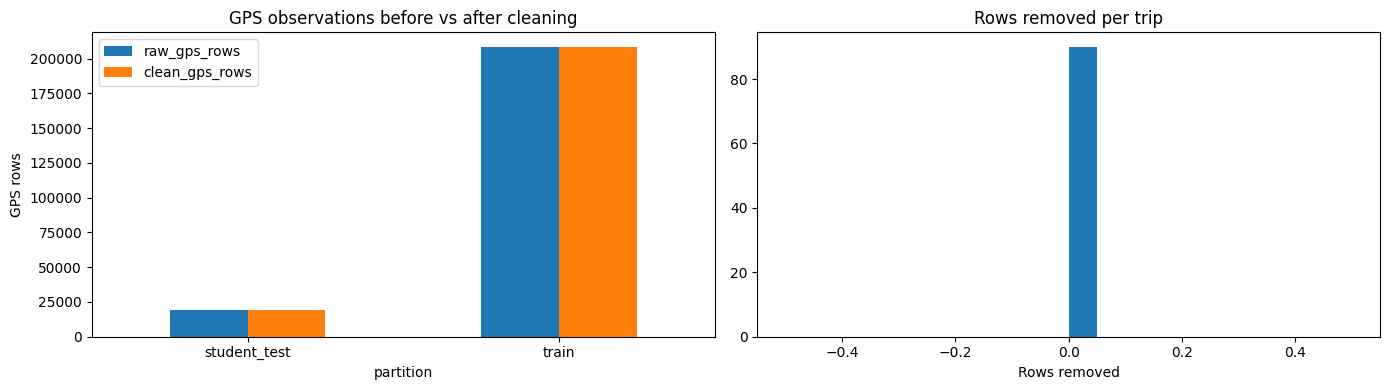

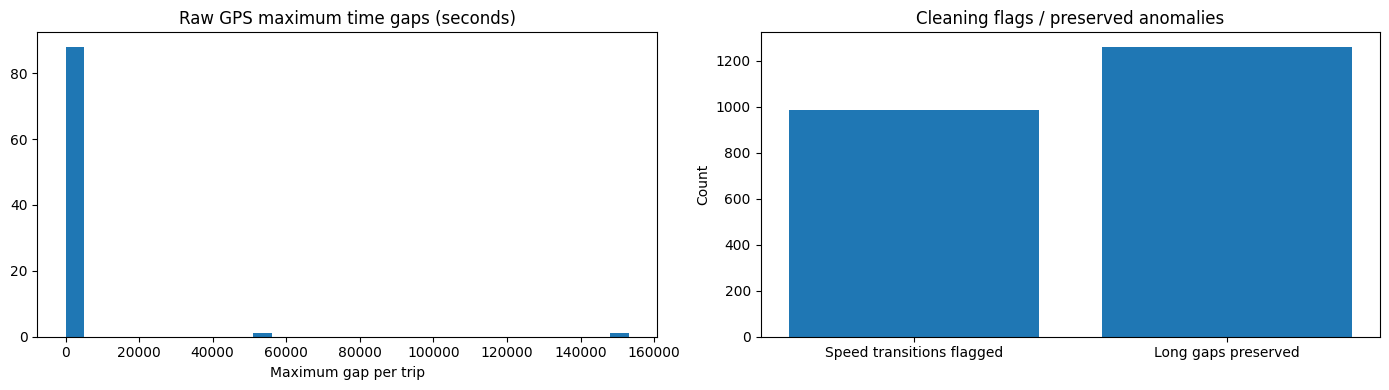

Cleaned GPS arrays ready: 90 trips


In [6]:
# Keep the original loader untouched for raw-data audit; use this loader for modelling.
MAX_REASONABLE_SPEED_MPS = 55.0  # ~198 km/h; conservative upper bound for this road-vehicle dataset
CLEANED_TRACKS = {}
cleaning_rows = []
cleaning_events = []

def clean_track_for_modelling(raw_track, trip_id, partition):
    raw = np.asarray(raw_track, dtype=float)
    n0 = len(raw)
    keep = np.isfinite(raw[:, :3]).all(axis=1)
    invalid_numeric = int((~keep).sum())
    work = raw[keep].copy()
    original_positions = np.flatnonzero(keep)

    geo = (np.abs(work[:,0]) <= 180) & (np.abs(work[:,1]) <= 90)
    invalid_geo = int((~geo).sum())
    work = work[geo]
    original_positions = original_positions[geo]

    # Remove exact consecutive duplicate GPS+timestamp rows only.
    if len(work):
        exact_dup = np.zeros(len(work), dtype=bool)
        exact_dup[1:] = np.all(work[1:] == work[:-1], axis=1)
        exact_duplicate_count = int(exact_dup.sum())
        work = work[~exact_dup]
        original_positions = original_positions[~exact_dup]
    else:
        exact_duplicate_count = 0

    # Keep the first row for a repeated timestamp. Preserve source order; never sort
    # GPS observations because sorting can change the actual trajectory sequence.
    if len(work):
        seen = set()
        timestamp_dup = np.zeros(len(work), dtype=bool)
        for i, ts in enumerate(work[:,2]):
            key = float(ts)
            if key in seen:
                timestamp_dup[i] = True
            else:
                seen.add(key)
        duplicate_timestamp_count = int(timestamp_dup.sum())
        work = work[~timestamp_dup]
        original_positions = original_positions[~timestamp_dup]
    else:
        duplicate_timestamp_count = 0

    # Flag (do not delete) non-increasing timestamps and extreme speed transitions.
    dt = np.diff(work[:,2]) if len(work) > 1 else np.array([])
    non_increasing = int((dt <= 0).sum())
    if len(work) > 1:
        step_dist = haversine_m(work[:-1,0], work[:-1,1], work[1:,0], work[1:,1])
        safe_dt = np.where(dt > 0, dt, np.nan)
        speeds = step_dist / safe_dt
        extreme_speed_steps = int(np.nansum(speeds > MAX_REASONABLE_SPEED_MPS))
        positive_dt = dt[dt > 0]
        fallback_dt = float(np.median(positive_dt)) if len(positive_dt) else 1.0
    else:
        speeds = np.array([])
        extreme_speed_steps = 0
        fallback_dt = 1.0

    CLEANED_TRACKS[(partition, str(trip_id))] = work
    removed = n0 - len(work)
    cleaning_rows.append({
        "partition":partition, "trip_id":str(trip_id),
        "raw_gps_rows":n0, "clean_gps_rows":len(work), "rows_removed":removed,
        "nonfinite_rows_removed":invalid_numeric,
        "invalid_coordinate_rows_removed":invalid_geo,
        "exact_consecutive_duplicates_removed":exact_duplicate_count,
        "duplicate_timestamp_rows_removed":duplicate_timestamp_count,
        "non_increasing_time_steps_remaining":non_increasing,
        "extreme_speed_steps_flagged":extreme_speed_steps,
        "long_gaps_gt_5s_preserved":int((dt > 5).sum()) if len(dt) else 0,
        "median_positive_dt_s":fallback_dt
    })
    if invalid_numeric: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Removed non-finite GPS/timestamp rows","count":invalid_numeric})
    if invalid_geo: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Removed out-of-range longitude/latitude rows","count":invalid_geo})
    if exact_duplicate_count: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Removed exact consecutive duplicate observations","count":exact_duplicate_count})
    if duplicate_timestamp_count: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Removed repeated-timestamp rows (first retained; source order preserved)","count":duplicate_timestamp_count})
    if non_increasing: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Flagged non-increasing timestamps; no reordering performed","count":non_increasing})
    if extreme_speed_steps: cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Flagged implausible speed transitions; speed feature capped, coordinates retained","count":extreme_speed_steps})
    if len(dt) and np.any(dt > 5): cleaning_events.append({"trip_id":str(trip_id),"partition":partition,"correction":"Preserved GPS gaps >5s; no synthetic interpolation","count":int((dt > 5).sum())})
    return work

for (part,tid),fs in sorted(TRIPS.items()):
    raw_track, nodes_raw, arcs_raw, route_raw = load_trip(fs)
    clean_track_for_modelling(raw_track,tid,part)

cleaning_audit_df = pd.DataFrame(cleaning_rows)
cleaning_events_df = pd.DataFrame(cleaning_events,
    columns=["trip_id","partition","correction","count"])
print("GPS CLEANING SUMMARY")
display(cleaning_audit_df.groupby("partition").agg(
    trips=("trip_id","count"),raw_rows=("raw_gps_rows","sum"),
    cleaned_rows=("clean_gps_rows","sum"),rows_removed=("rows_removed","sum"),
    extreme_speed_steps_flagged=("extreme_speed_steps_flagged","sum"),
    long_gaps_preserved=("long_gaps_gt_5s_preserved","sum")).reset_index())
print("Correction log (only actions/flags that actually occurred):")
display(cleaning_events_df if len(cleaning_events_df) else pd.DataFrame([{
    "trip_id":"ALL","partition":"ALL",
    "correction":"No rows required removal; raw observations retained",
    "count":0
}]))
display(cleaning_audit_df.head(12))

# Before/after data-volume plot and trip-level removal plot, based on actual counts.
fig,ax=plt.subplots(1,2,figsize=(14,4))
part_summary=cleaning_audit_df.groupby("partition")[["raw_gps_rows","clean_gps_rows"]].sum()
part_summary.plot(kind="bar",ax=ax[0],title="GPS observations before vs after cleaning")
ax[0].set_ylabel("GPS rows"); ax[0].tick_params(axis="x",rotation=0)
ax[1].hist(cleaning_audit_df["rows_removed"],bins=20)
ax[1].set_title("Rows removed per trip"); ax[1].set_xlabel("Rows removed")
plt.tight_layout(); plt.show()

fig,ax=plt.subplots(1,2,figsize=(14,4))
ax[0].hist(quality_df["max_gap_s"].dropna(),bins=30)
ax[0].set_title("Raw GPS maximum time gaps (seconds)")
ax[0].set_xlabel("Maximum gap per trip")
ax[1].bar(["Speed transitions flagged","Long gaps preserved"],
          [cleaning_audit_df["extreme_speed_steps_flagged"].sum(),
           cleaning_audit_df["long_gaps_gt_5s_preserved"].sum()])
ax[1].set_title("Cleaning flags / preserved anomalies")
ax[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

# Cleaner used only by modelling and map code; nodes/arcs/route are never renumbered.
def load_trip_cleaned(files, trip_id, partition):
    _, nodes, arcs, route = load_trip(files)
    track = CLEANED_TRACKS.get((partition,str(trip_id)))
    if track is None:
        raw,_,_,_ = load_trip(files)
        track = clean_track_for_modelling(raw,trip_id,partition)
    return track, nodes, arcs, route

print("Cleaned GPS arrays ready:",len(CLEANED_TRACKS),"trips")

## 5B. Geographical EDA: cleaned training trajectory and supplied reference route

The map uses one actual training trip. It shows cleaned GPS observations and the supplied reference route on the road network. This is an exploratory view, not a model prediction.

In [7]:
import folium
from IPython.display import display
eda_trip=sorted(tid for part,tid in TRIPS if part=="train")[0]
eda_files=TRIPS[("train",eda_trip)]
eda_track,eda_nodes,eda_arcs,eda_route=load_trip_cleaned(eda_files,eda_trip,"train")
eda_center=[float(np.mean(eda_track[:,1])),float(np.mean(eda_track[:,0]))]
eda_map=folium.Map(location=eda_center,zoom_start=13,control_scale=True)
gps_points=[(float(lat),float(lon)) for lon,lat,_ in eda_track]
folium.PolyLine(gps_points,color="blue",weight=3,opacity=.85,tooltip="Cleaned GPS trajectory").add_to(eda_map)
valid_route=eda_route[(eda_route>=0)&(eda_route<len(eda_arcs))]
# Keep the map responsive by rendering a bounded number of reference arcs.
for aid in valid_route[:2500]:
    u,v=eda_arcs[int(aid)]
    folium.PolyLine([(float(eda_nodes[u,1]),float(eda_nodes[u,0])),
                     (float(eda_nodes[v,1]),float(eda_nodes[v,0]))],
                    color="green",weight=2,opacity=.65,tooltip="Reference route").add_to(eda_map)
folium.LayerControl().add_to(eda_map)
EDA_MAP_PATH=str(Path.cwd()/"pathsnap_eda_training_trip.html")
eda_map.save(EDA_MAP_PATH)
display(eda_map)
print("EDA training trip:",eda_trip,"| saved:",EDA_MAP_PATH)

EDA training trip: 00000001 | saved: /content/pathsnap_eda_training_trip.html


## 6. Candidate road-segment generation and feature engineering

For each GPS observation, retrieve the nearest `K` road-segment midpoints using a spatial KD-tree, then calculate exact point-to-segment distance in a local metre coordinate system. Features include distance, segment length, bearing difference, GPS speed, GPS heading, time gap, and neighbouring-observation movement consistency.

**Label construction:** for each observation, find the nearest segment among the trip's supplied `.route` arcs. A candidate is positive when its `arc_id` equals that nearest reference-route arc. This converts the route sequence into approximate observation-level labels. Candidate miss rate is measured before model fitting; it is not hidden by forcing the reference segment into the candidate list.

In [8]:
K_CANDIDATES = 6
MAX_TRAIN_OBS_PER_TRIP = 400  # speed/memory guard; set None to use all observations
EARTH_R = 6371000.0

def local_xy(lon, lat, lon0, lat0):
    x=np.radians(lon-lon0)*EARTH_R*np.cos(np.radians(lat0))
    y=np.radians(lat-lat0)*EARTH_R
    return np.column_stack([x,y])

def point_segment_distance(P, A, B):
    AB=B-A
    denom=np.sum(AB*AB,axis=1)
    denom=np.maximum(denom,1e-9)
    AP=P-A
    u=np.clip(np.sum(AP*AB,axis=1)/denom,0,1)
    Q=A+u[:,None]*AB
    return np.sqrt(np.sum((P-Q)**2,axis=1))

def bearing_xy(v):
    return (np.degrees(np.arctan2(v[:,0],v[:,1]))+360)%360

def angle_diff(a,b):
    return np.abs((a-b+180)%360-180)

def build_trip_candidates(files, trip_id, partition, k=K_CANDIDATES):
    track,nodes,arcs,route=load_trip_cleaned(files,trip_id,partition)
    # Remove invalid GPS rows; retain original row order and timestamp.
    valid=np.isfinite(track).all(axis=1)
    track=track[valid]
    if len(track)<2 or len(arcs)==0 or len(route)==0: return None, {"reason":"empty/invalid data"}
    # Remove implausible coordinate rows.
    valid_geo=(np.abs(track[:,0])<=180)&(np.abs(track[:,1])<=90)
    track=track[valid_geo]
    if len(track)<2: return None, {"reason":"too few valid GPS points"}
    if partition=="train" and MAX_TRAIN_OBS_PER_TRIP and len(track)>MAX_TRAIN_OBS_PER_TRIP:
        take=np.linspace(0,len(track)-1,MAX_TRAIN_OBS_PER_TRIP).astype(int)
        track=track[take]
    lon0=float(np.mean(track[:,0])); lat0=float(np.mean(track[:,1]))
    P=local_xy(track[:,0],track[:,1],lon0,lat0)
    N=local_xy(nodes[:,0],nodes[:,1],lon0,lat0)
    starts=arcs[:,0]; ends=arcs[:,1]
    A=N[starts]; B=N[ends]; mids=(A+B)/2
    segvec=B-A
    seglen=np.sqrt((segvec**2).sum(axis=1))
    segbearing=bearing_xy(segvec)
    tree=cKDTree(mids)
    kk=min(k,len(arcs))
    _, cand=tree.query(P,k=kk)
    if kk==1: cand=cand[:,None]
    # GPS motion features
    dxy=np.diff(P,axis=0,prepend=P[:1])
    dt=np.diff(track[:,2],prepend=track[0,2])
    positive_dt=dt[dt>0]
    fallback_dt=float(np.median(positive_dt)) if len(positive_dt) else 1.0
    dt=np.where(dt>0,dt,fallback_dt)
    speed=np.sqrt((dxy**2).sum(axis=1))/dt
    speed=np.clip(speed,0,MAX_REASONABLE_SPEED_MPS)
    heading=bearing_xy(dxy)
    # Reference route arc geometries; invalid route ids are discarded.
    rids=np.unique(route[(route>=0)&(route<len(arcs))])
    if len(rids)==0: return None, {"reason":"no valid route arc ids"}
    # Find nearest reference route segment for every GPS point (chunked).
    refdist=np.empty(len(P)); refarc=np.empty(len(P),dtype=int)
    for st in range(0,len(P),256):
        en=min(st+256,len(P))
        # distance matrix for point to every reference segment
        pp=np.repeat(P[st:en],len(rids),axis=0)
        aa=np.tile(A[rids],(en-st,1)); bb=np.tile(B[rids],(en-st,1))
        dd=point_segment_distance(pp,aa,bb).reshape(en-st,len(rids))
        ix=np.argmin(dd,axis=1)
        refdist[st:en]=dd[np.arange(en-st),ix]
        refarc[st:en]=rids[ix]
    rows=[]
    for i in range(len(P)):
        ci=cand[i]
        dist=point_segment_distance(np.repeat(P[i:i+1],kk,axis=0),A[ci],B[ci])
        to_mid=np.sqrt(((mids[ci]-P[i])**2).sum(axis=1))
        bdiff=angle_diff(np.full(kk,heading[i]),segbearing[ci])
        for j,aid in enumerate(ci):
            rows.append((trip_id,partition,i,int(aid),int(aid==refarc[i]),
                         float(dist[j]),float(to_mid[j]),float(seglen[aid]),
                         float(bdiff[j]),float(speed[i]),float(dt[i]),
                         float(refdist[i])))
    cols=["trip_id","partition","obs_idx","arc_id","label","point_seg_dist_m",
          "midpoint_dist_m","segment_length_m","heading_diff_deg","gps_speed_mps",
          "time_delta_s","reference_snap_dist_m"]
    df=pd.DataFrame(rows,columns=cols)
    # Candidate rank and within-observation relative distances.
    df["candidate_rank"]=df.groupby(["trip_id","obs_idx"])["point_seg_dist_m"].rank(method="first")
    df["dist_from_best_m"]=df["point_seg_dist_m"]-df.groupby(["trip_id","obs_idx"])["point_seg_dist_m"].transform("min")
    diag={"gps_observations":len(P),"candidate_rows":len(df),
          "candidate_hit_rate":float(df.groupby("obs_idx")["label"].max().mean()),
          "reference_snap_median":float(np.median(refdist)),
          "reference_snap_p95":float(np.percentile(refdist,95))}
    return df,diag

all_frames=[]; diagnostics=[]
for (part,tid),fs in sorted(TRIPS.items()):
    if part not in ["train","student_test"]: continue
    try:
        frame,diag=build_trip_candidates(fs,tid,part)
        if frame is not None:
            all_frames.append(frame); diagnostics.append({"partition":part,"trip_id":tid,**diag})
    except Exception as e:
        diagnostics.append({"partition":part,"trip_id":tid,"error":str(e)})
if not all_frames:
    error_table = pd.DataFrame(diagnostics)
    display(error_table)
    raise RuntimeError("No trip produced candidate rows. Check the ZIP layout and file contents above.")
candidate_df=pd.concat(all_frames,ignore_index=True)
diagnostics_df=pd.DataFrame(diagnostics)
if "partition" not in diagnostics_df or not {"train","student_test"}.issubset(set(diagnostics_df["partition"])):
    raise RuntimeError("Candidate generation did not produce both train and student_test partitions.")
display(diagnostics_df.groupby("partition")[["gps_observations","candidate_rows","candidate_hit_rate","reference_snap_median","reference_snap_p95"]].mean())
print("Candidate table:", candidate_df.shape)

,gps_observations,candidate_rows,candidate_hit_rate,reference_snap_median,reference_snap_p95
partition,,,,,
student_test,1916.0000,11496.000,0.872262,5.035486,16.279213
train,398.7875,2392.725,0.856947,8.103136,23.830443


Candidate table: (306378, 14)


## 7. Validate label and candidate quality before training

A candidate hit rate below 1 means the nearest reference-route arc is absent from the top-K candidates for some observations. Those observations cannot be correctly classified by this candidate set. Increase `K_CANDIDATES` and rerun Section 6 if memory/time allows. Also inspect reference snap distances: large values may indicate GPS noise, an incomplete route, coordinate issues, or the approximation used to align route arcs to observations.

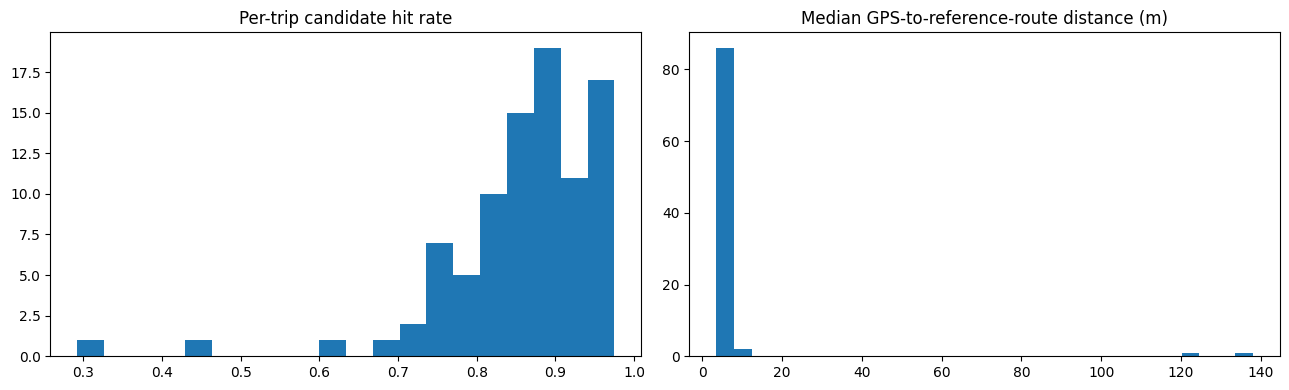

,partition,trip_id,gps_observations,candidate_rows,candidate_hit_rate,reference_snap_median,reference_snap_p95
36,train,00000033,400,2400,0.2925,124.450296,142.358160
54,train,00000054,400,2400,0.4600,138.082204,209.047259
22,train,00000016,400,2400,0.6175,6.570126,26.441452
12,train,00000003,400,2400,0.6925,4.214348,13.876258
72,train,00000079,400,2400,0.7100,4.392613,13.356386
10,train,00000001,400,2400,0.7325,4.218121,13.377436
45,train,00000043,400,2400,0.7400,12.041457,72.998642
81,train,00000089,400,2400,0.7425,4.207749,15.303701
33,train,00000029,400,2400,0.7550,4.288652,14.007269
55,train,00000055,400,2400,0.7600,3.999185,11.303011


In [9]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].hist(diagnostics_df["candidate_hit_rate"].dropna(),bins=20)
ax[0].set_title("Per-trip candidate hit rate")
ax[1].hist(diagnostics_df["reference_snap_median"].dropna(),bins=30)
ax[1].set_title("Median GPS-to-reference-route distance (m)")
plt.tight_layout(); plt.show()
display(diagnostics_df.sort_values("candidate_hit_rate").head(10))


## 8. Build training and student-testing matrices

Each observation contributes up to K candidate rows. The target is binary relevance (1 = candidate matches the geometrically aligned reference route arc). At inference, candidates are ranked by predicted positive probability and the highest-scoring candidate is selected. GroupKFold keeps all candidate rows from a trip in one fold.

In [10]:
if "candidate_df" not in globals() or candidate_df.empty:
    raise RuntimeError("candidate_df is missing or empty. Run dataset extraction and candidate-generation cells first.")

FEATURES=["point_seg_dist_m","midpoint_dist_m","segment_length_m","heading_diff_deg",
          "gps_speed_mps","time_delta_s","candidate_rank","dist_from_best_m"]
train_df=candidate_df[candidate_df.partition=="train"].copy().reset_index(drop=True)
student_df=candidate_df[candidate_df.partition=="student_test"].copy().reset_index(drop=True)
if train_df.empty or student_df.empty:
    raise RuntimeError("Training or student-testing candidate table is empty. Check the partition folder names.")
missing_features=[f for f in FEATURES if f not in train_df.columns]
if missing_features:
    raise RuntimeError(f"Missing engineered feature columns: {missing_features}")

X_train=train_df[FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0).astype(np.float32)
y_train=train_df["label"].astype(int).reset_index(drop=True)
groups=train_df["trip_id"].astype(str).reset_index(drop=True)
X_student=student_df[FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0).astype(np.float32)
y_student=student_df["label"].astype(int).reset_index(drop=True)
if y_train.nunique()<2:
    raise RuntimeError("Training labels contain only one class. Candidate/label construction must be inspected.")
if groups.nunique()<5:
    raise RuntimeError(f"Only {groups.nunique()} training trips available; need at least 5 for GroupKFold.")
print("Training rows:",len(train_df),"positive rate:",round(y_train.mean(),4))
print("Training trips:",groups.nunique(),"Student trips:",student_df.trip_id.nunique())
print("Features:",FEATURES)


Training rows: 191418 positive rate: 0.1428
Training trips: 80 Student trips: 10
Features: ['point_seg_dist_m', 'midpoint_dist_m', 'segment_length_m', 'heading_diff_deg', 'gps_speed_mps', 'time_delta_s', 'candidate_rank', 'dist_from_best_m']


## 9. Evaluation helpers: observation-level ranking metrics

The model is trained on candidate rows, but reported Top-1 Accuracy and Macro F1 are calculated at the GPS-observation level after ranking each observation's candidate segments. Since there is one selected segment per observation, macro F1 is computed over the selected arc IDs present in the reference and predicted labels; interpret it alongside Top-1 accuracy and candidate hit rate.

In [11]:
def rank_predictions(frame, probabilities):
    if len(frame) != len(probabilities):
        raise ValueError("Prediction count does not match candidate-row count.")
    temp=frame[["trip_id","obs_idx","arc_id","label"]].copy()
    temp["prob"]=np.asarray(probabilities, dtype=float)
    temp=temp.sort_values(["trip_id","obs_idx","prob"],ascending=[True,True,False])
    chosen=temp.groupby(["trip_id","obs_idx"],as_index=False,sort=True).first()
    return chosen

def observation_metrics(frame, probabilities):
    chosen=rank_predictions(frame,probabilities)
    truth=frame[frame.label==1].drop_duplicates(["trip_id","obs_idx"]).set_index(["trip_id","obs_idx"])["arc_id"]
    pred=chosen.set_index(["trip_id","obs_idx"])["arc_id"]
    common=truth.index.intersection(pred.index)
    if len(common)==0:
        return {"conditional_accuracy":np.nan,"coverage":0.0,"effective_accuracy":0.0,"macro_f1":np.nan},chosen
    yt=truth.loc[common].to_numpy()
    yp=pred.loc[common].to_numpy()
    coverage=float(len(common)/frame[["trip_id","obs_idx"]].drop_duplicates().shape[0])
    acc=float(np.mean(yt==yp))
    f1=float(f1_score(yt,yp,average="macro",zero_division=0))
    return {"conditional_accuracy":acc,"coverage":coverage,
            "effective_accuracy":acc*coverage,"macro_f1":f1},chosen


## 10. Group-aware cross-validation and five model families

We use trip-level GroupKFold. Each model is compared using out-of-fold candidate probabilities, then observation-level ranking. CPU models are included as baselines; XGBoost attempts GPU training first and falls back cleanly if CUDA is unavailable.

In [12]:
def make_models(use_gpu=True):
    return {
      "Random Forest": RandomForestClassifier(n_estimators=60,min_samples_leaf=2,
                         class_weight="balanced_subsample",n_jobs=-1,random_state=SEED),
      "Extra Trees": ExtraTreesClassifier(n_estimators=70,min_samples_leaf=2,
                         class_weight="balanced",n_jobs=-1,random_state=SEED),
      "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=80,learning_rate=0.08,
                         max_leaf_nodes=31,l2_regularization=1.0,random_state=SEED),
      "LightGBM": lgb.LGBMClassifier(n_estimators=110,learning_rate=0.05,num_leaves=31,
                         max_depth=-1,subsample=0.85,colsample_bytree=0.9,
                         class_weight="balanced",verbosity=-1,random_state=SEED,n_jobs=-1),
      "XGBoost": XGBClassifier(n_estimators=110,max_depth=7,learning_rate=0.06,
                         subsample=0.85,colsample_bytree=0.9,min_child_weight=3,
                         reg_lambda=2,objective="binary:logistic",eval_metric="logloss",
                         tree_method="hist",device="cuda" if use_gpu else "cpu",
                         n_jobs=-1,random_state=SEED)
    }

# Rebuild all training objects here as a guard against running cells out of order.
if "candidate_df" not in globals() or candidate_df.empty:
    raise RuntimeError("candidate_df is missing or empty. Run dataset extraction and candidate generation first.")
# Re-create the matrices here as well, so this section does not depend on a stale `groups` variable.
FEATURES=["point_seg_dist_m","midpoint_dist_m","segment_length_m","heading_diff_deg",
          "gps_speed_mps","time_delta_s","candidate_rank","dist_from_best_m"]
train_df=candidate_df[candidate_df.partition=="train"].copy().reset_index(drop=True)
student_df=candidate_df[candidate_df.partition=="student_test"].copy().reset_index(drop=True)
if train_df.empty or student_df.empty:
    raise RuntimeError("Training or student-testing candidate rows are missing. Check partition names.")
X_train=train_df[FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0).astype(np.float32)
y_train=train_df["label"].astype(int).reset_index(drop=True)
groups=train_df["trip_id"].astype(str).reset_index(drop=True)
X_student=student_df[FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0).astype(np.float32)
y_student=student_df["label"].astype(int).reset_index(drop=True)
N_SPLITS=min(3,groups.nunique())
if N_SPLITS < 2:
    raise RuntimeError("Group-aware cross-validation requires at least two training trips.")
gkf=GroupKFold(n_splits=N_SPLITS)
cv_rows=[]
cv_oof_probabilities={}
for name,model in make_models(use_gpu=True).items():
    oof=np.zeros(len(train_df),dtype=float)
    for fold,(tr_idx,va_idx) in enumerate(gkf.split(X_train,y_train,groups),1):
        m=clone(model)
        try:
            m.fit(X_train.iloc[tr_idx],y_train.iloc[tr_idx])
        except Exception as e:
            if name=="XGBoost":
                print("XGBoost GPU unavailable; retrying this fold on CPU:",str(e)[:180])
                m.set_params(device="cpu")
                m.fit(X_train.iloc[tr_idx],y_train.iloc[tr_idx])
            else:
                raise RuntimeError(f"{name} failed in CV fold {fold}: {e}") from e
        oof[va_idx]=m.predict_proba(X_train.iloc[va_idx])[:,1]
    cv_oof_probabilities[name]=oof.copy()
    met,_=observation_metrics(train_df,oof)
    cv_candidate_logloss=float(log_loss(y_train,oof,labels=[0,1]))
    cv_rows.append({"model":name,"cv_top1_accuracy_on_candidates":met["conditional_accuracy"],
                    "cv_candidate_coverage":met["coverage"],
                    "cv_effective_top1_accuracy":met["effective_accuracy"],
                    "cv_macro_f1":met["macro_f1"],"cv_candidate_log_loss":cv_candidate_logloss})
    print(name, "CV Top-1:",round(met["conditional_accuracy"],4),
          "Coverage:",round(met["coverage"],4),
          "Effective Top-1:",round(met["effective_accuracy"],4),
          "CV Macro-F1:",round(met["macro_f1"],4))
cv_results=pd.DataFrame(cv_rows).sort_values("cv_macro_f1",ascending=False).reset_index(drop=True)
display(cv_results)


Random Forest CV Top-1: 0.8638 Coverage: 0.8567 Effective Top-1: 0.7401 CV Macro-F1: 0.8137
Extra Trees CV Top-1: 0.859 Coverage: 0.8567 Effective Top-1: 0.7359 CV Macro-F1: 0.7995
Hist Gradient Boosting CV Top-1: 0.8661 Coverage: 0.8567 Effective Top-1: 0.742 CV Macro-F1: 0.8196
LightGBM CV Top-1: 0.8661 Coverage: 0.8567 Effective Top-1: 0.742 CV Macro-F1: 0.8196
XGBoost CV Top-1: 0.8666 Coverage: 0.8567 Effective Top-1: 0.7424 CV Macro-F1: 0.8207


,model,cv_top1_accuracy_on_candidates,cv_candidate_coverage,cv_effective_top1_accuracy,cv_macro_f1,cv_candidate_log_loss
0,XGBoost,0.866567,0.856722,0.742407,0.820739,0.133836
1,LightGBM,0.866054,0.856722,0.741968,0.819643,0.195601
2,Hist Gradient Boosting,0.866091,0.856722,0.741999,0.819579,0.135075
3,Random Forest,0.863823,0.856722,0.740056,0.813740,0.188638
4,Extra Trees,0.859030,0.856722,0.735950,0.799494,0.184067


## 11. Fit all models and compare on the student-testing partition

Student-testing data is reserved for development-stage comparison by the supplied guidelines. It is not used in cross-validation or fitting. The notebook reports actual results from this run only.

In [13]:
fitted_models={}
student_rows=[]
student_predictions={}
student_probabilities={}
for name,base_model in make_models(use_gpu=True).items():
    model=clone(base_model)
    try:
        model.fit(X_train,y_train)
    except Exception as e:
        if name=="XGBoost":
            print("XGBoost GPU unavailable; retrying final fit on CPU:",str(e)[:160])
            model.set_params(device="cpu")
            model.fit(X_train,y_train)
        else:
            raise RuntimeError(f"{name} final fit failed: {e}") from e
    fitted_models[name]=model
    probs=model.predict_proba(X_student)[:,1]
    student_probabilities[name]=probs.copy()
    student_candidate_logloss=float(log_loss(y_student,probs,labels=[0,1]))
    met,chosen=observation_metrics(student_df,probs)
    student_rows.append({"model":name,"student_top1_accuracy_on_candidates":met["conditional_accuracy"],
                         "student_candidate_coverage":met["coverage"],
                         "student_effective_top1_accuracy":met["effective_accuracy"],
                         "student_macro_f1":met["macro_f1"],"student_candidate_log_loss":student_candidate_logloss})
    student_predictions[name]=chosen
comparison=cv_results.merge(pd.DataFrame(student_rows),on="model").sort_values("cv_macro_f1",ascending=False)
display(comparison)


,model,cv_top1_accuracy_on_candidates,cv_candidate_coverage,cv_effective_top1_accuracy,cv_macro_f1,cv_candidate_log_loss,student_top1_accuracy_on_candidates,student_candidate_coverage,student_effective_top1_accuracy,student_macro_f1,student_candidate_log_loss
0,XGBoost,0.866567,0.856722,0.742407,0.820739,0.133836,0.811057,0.877035,0.711326,0.682125,0.156040
1,LightGBM,0.866054,0.856722,0.741968,0.819643,0.195601,0.811533,0.877035,0.711743,0.680081,0.217664
2,Hist Gradient Boosting,0.866091,0.856722,0.741999,0.819579,0.135075,0.811473,0.877035,0.711691,0.681040,0.157467
3,Random Forest,0.863823,0.856722,0.740056,0.813740,0.188638,0.810819,0.877035,0.711117,0.677234,0.184816
4,Extra Trees,0.859030,0.856722,0.735950,0.799494,0.184067,0.805820,0.877035,0.706733,0.668956,0.198057


## 12. Visualise actual model comparisons and diagnostics

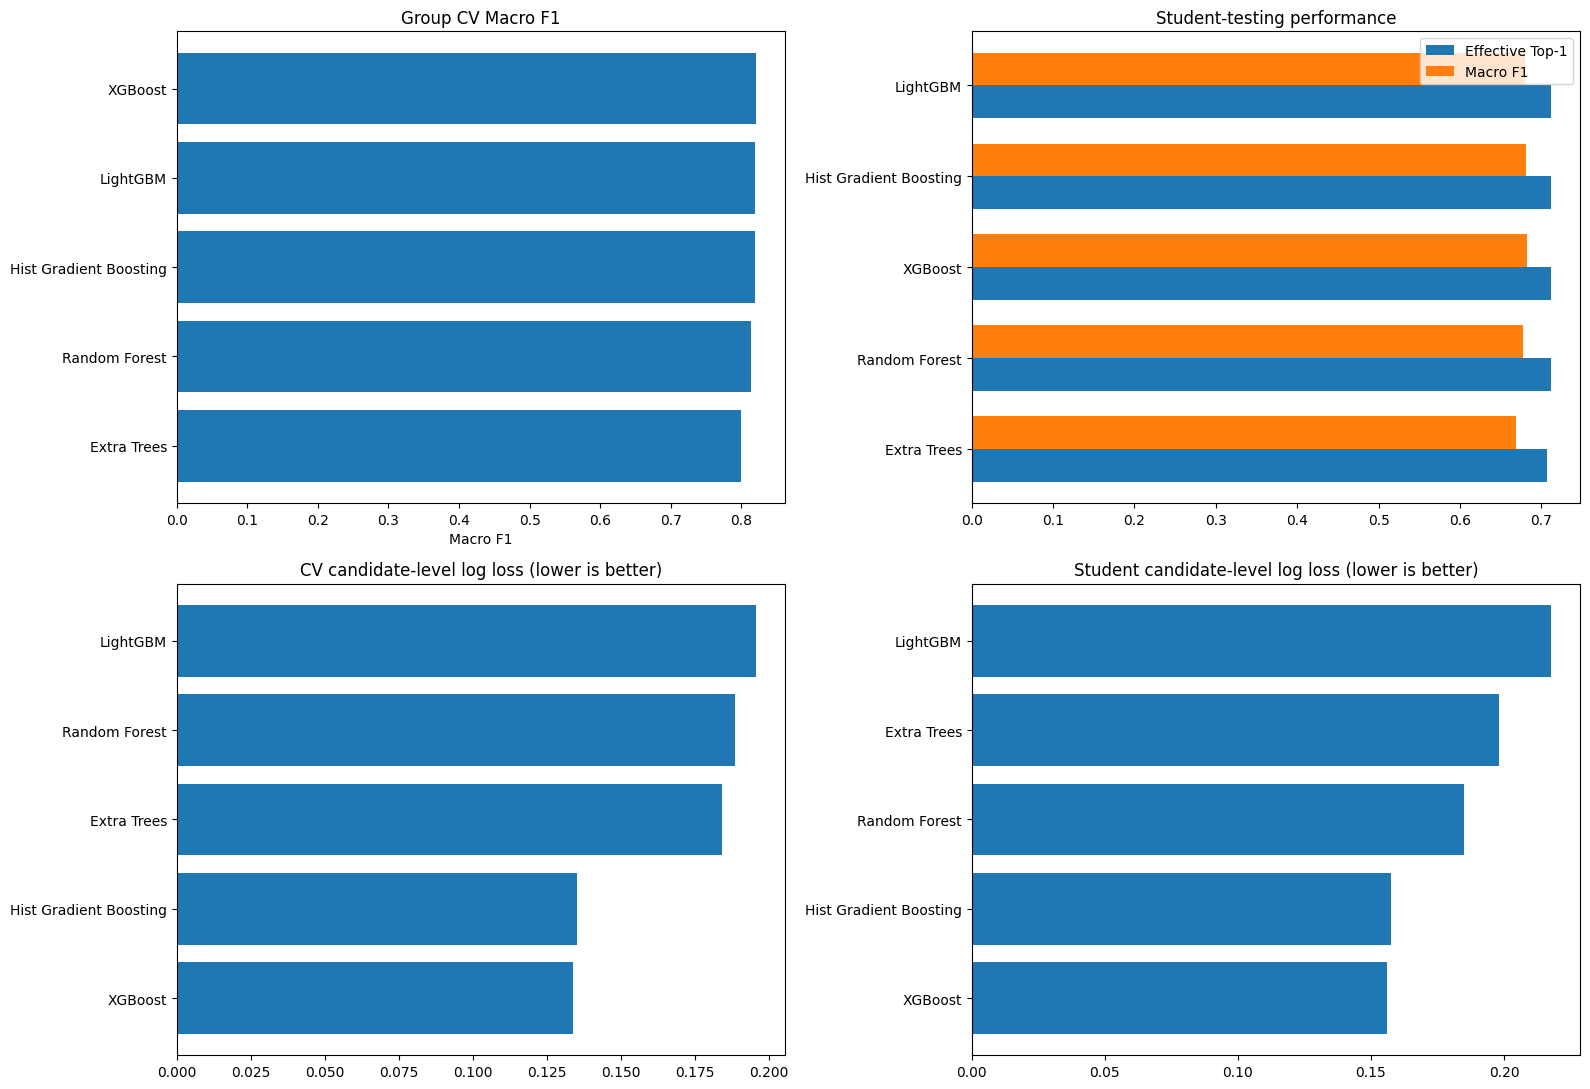

Log loss is binary candidate relevance loss; Top-1 is observation-level ranking.


,model,cv_macro_f1,cv_candidate_log_loss,student_top1_accuracy_on_candidates,student_candidate_coverage,student_effective_top1_accuracy,student_macro_f1,student_candidate_log_loss
0,XGBoost,0.820739,0.133836,0.811057,0.877035,0.711326,0.682125,0.156040
1,LightGBM,0.819643,0.195601,0.811533,0.877035,0.711743,0.680081,0.217664
2,Hist Gradient Boosting,0.819579,0.135075,0.811473,0.877035,0.711691,0.681040,0.157467
3,Random Forest,0.813740,0.188638,0.810819,0.877035,0.711117,0.677234,0.184816
4,Extra Trees,0.799494,0.184067,0.805820,0.877035,0.706733,0.668956,0.198057


In [14]:
# All visualisations below are calculated from real out-of-fold and student-test predictions.
fig,ax=plt.subplots(2,2,figsize=(16,11))
p1=comparison.sort_values("cv_macro_f1")
ax[0,0].barh(p1["model"],p1["cv_macro_f1"])
ax[0,0].set_title("Group CV Macro F1"); ax[0,0].set_xlabel("Macro F1")
p2=comparison.sort_values("student_effective_top1_accuracy")
y=np.arange(len(p2)); w=.36
ax[0,1].barh(y-w/2,p2["student_effective_top1_accuracy"],height=w,label="Effective Top-1")
ax[0,1].barh(y+w/2,p2["student_macro_f1"],height=w,label="Macro F1")
ax[0,1].set_yticks(y); ax[0,1].set_yticklabels(p2["model"])
ax[0,1].set_title("Student-testing performance"); ax[0,1].legend()
p3=comparison.sort_values("cv_candidate_log_loss")
ax[1,0].barh(p3["model"],p3["cv_candidate_log_loss"])
ax[1,0].set_title("CV candidate-level log loss (lower is better)")
p4=comparison.sort_values("student_candidate_log_loss")
ax[1,1].barh(p4["model"],p4["student_candidate_log_loss"])
ax[1,1].set_title("Student candidate-level log loss (lower is better)")
plt.tight_layout(); plt.show()
print("Log loss is binary candidate relevance loss; Top-1 is observation-level ranking.")
display(comparison[["model","cv_macro_f1","cv_candidate_log_loss",
    "student_top1_accuracy_on_candidates","student_candidate_coverage",
    "student_effective_top1_accuracy","student_macro_f1",
    "student_candidate_log_loss"]].sort_values("cv_macro_f1",ascending=False))

## 12A. Confusion matrices and actual boosting training histories

Confusion matrices are calculated from student-testing candidate probabilities. XGBoost and LightGBM expose iteration-wise evaluation histories; their real training and validation log-loss curves are plotted below. No curves are fabricated for Random Forest, Extra Trees or HistGradientBoosting.

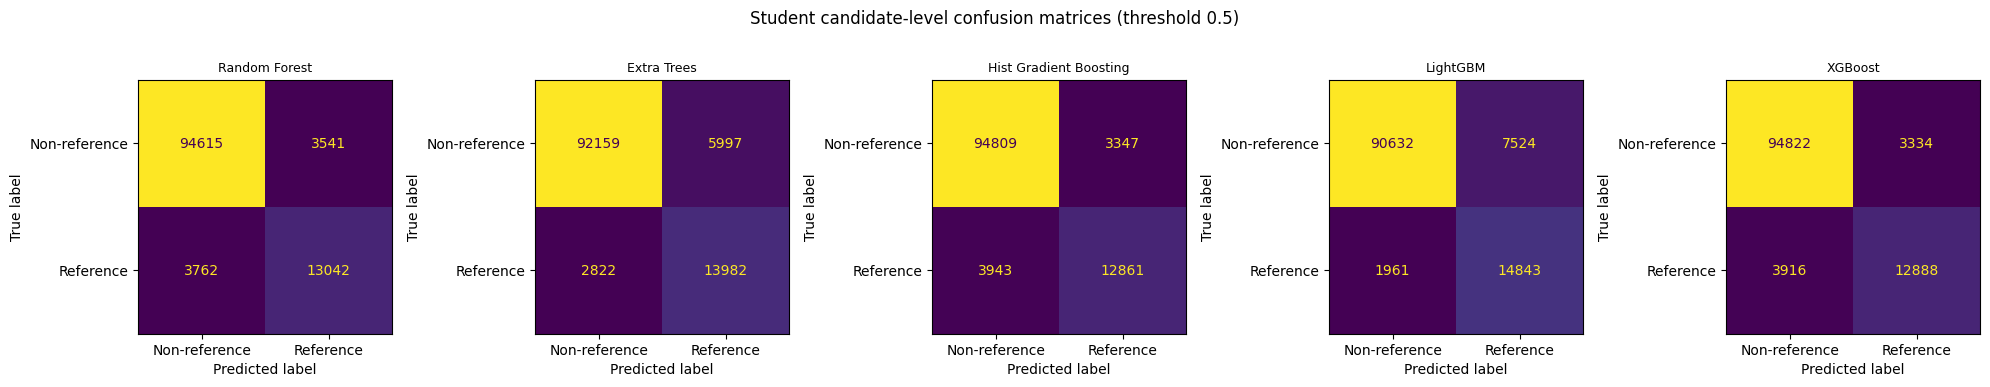

History split: 64 training trips; 16 validation trips


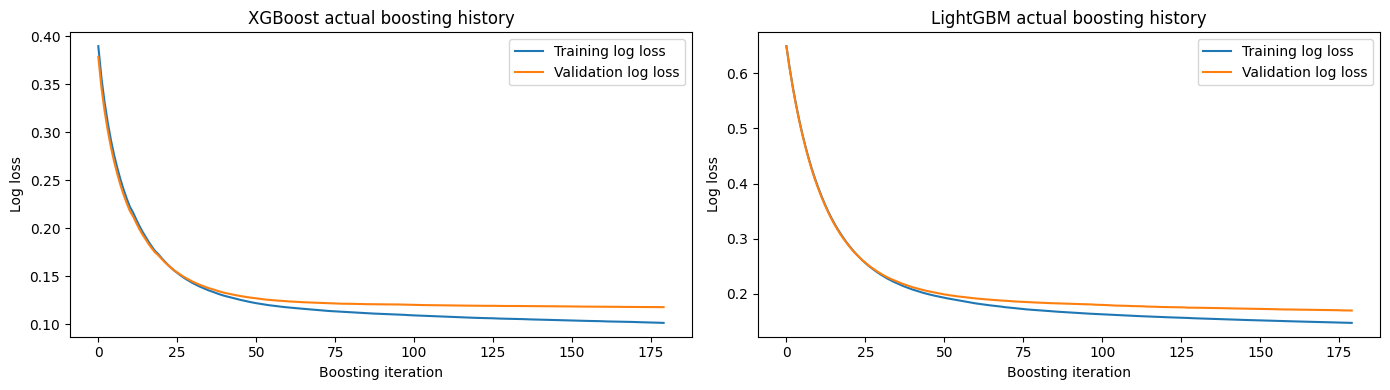

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit

fig,axes=plt.subplots(1,len(student_probabilities),figsize=(4*len(student_probabilities),4))
if len(student_probabilities)==1: axes=[axes]
for ax,(name,prob) in zip(axes,student_probabilities.items()):
    cm=confusion_matrix(y_student,(prob>=0.5).astype(int),labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=["Non-reference","Reference"]).plot(
        ax=ax,colorbar=False,values_format="d")
    ax.set_title(name,fontsize=9)
plt.suptitle("Student candidate-level confusion matrices (threshold 0.5)")
plt.tight_layout(); plt.show()

# A held-out set of whole trips prevents observations from the same trip leaking across sets.
gss=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED)
fit_idx,val_idx=next(gss.split(X_train,y_train,groups))
X_fit,y_fit=X_train.iloc[fit_idx],y_train.iloc[fit_idx]
X_val,y_val=X_train.iloc[val_idx],y_train.iloc[val_idx]
history_records={}
print("History split:",groups.iloc[fit_idx].nunique(),"training trips;",
      groups.iloc[val_idx].nunique(),"validation trips")

# XGBoost: actual per-boosting-round log loss.
xgb_hist_model=XGBClassifier(n_estimators=180,max_depth=7,learning_rate=.06,
    subsample=.85,colsample_bytree=.9,min_child_weight=3,reg_lambda=2,
    objective="binary:logistic",eval_metric="logloss",tree_method="hist",
    device="cuda",n_jobs=-1,random_state=SEED)
try:
    xgb_hist_model.fit(X_fit,y_fit,eval_set=[(X_fit,y_fit),(X_val,y_val)],verbose=False)
except Exception as e:
    print("XGBoost GPU history fallback to CPU:",str(e)[:180])
    xgb_hist_model.set_params(device="cpu")
    xgb_hist_model.fit(X_fit,y_fit,eval_set=[(X_fit,y_fit),(X_val,y_val)],verbose=False)
xh=xgb_hist_model.evals_result()
history_records["XGBoost"]={"training":xh["validation_0"]["logloss"],
                             "validation":xh["validation_1"]["logloss"]}

# LightGBM: real evaluation history (CPU unless a separately built GPU-enabled LightGBM is installed).
lgb_hist_model=lgb.LGBMClassifier(n_estimators=180,learning_rate=.06,num_leaves=31,
    class_weight="balanced",verbosity=-1,random_state=SEED,n_jobs=-1)
lgb_eval={}
lgb_hist_model.fit(X_fit,y_fit,eval_set=[(X_fit,y_fit),(X_val,y_val)],
    eval_metric="binary_logloss",
    callbacks=[lgb.record_evaluation(lgb_eval),lgb.log_evaluation(0)])
lgb_keys=list(lgb_eval)
if len(lgb_keys)>=2:
    history_records["LightGBM"]={"training":lgb_eval[lgb_keys[0]]["binary_logloss"],
                                 "validation":lgb_eval[lgb_keys[1]]["binary_logloss"]}

fig,axes=plt.subplots(1,len(history_records),figsize=(7*len(history_records),4))
if len(history_records)==1: axes=[axes]
for ax,(name,h) in zip(axes,history_records.items()):
    ax.plot(h["training"],label="Training log loss")
    ax.plot(h["validation"],label="Validation log loss")
    ax.set_title(name+" actual boosting history")
    ax.set_xlabel("Boosting iteration"); ax.set_ylabel("Log loss"); ax.legend()
plt.tight_layout(); plt.show()

## 13. Select a model and perform Bayesian hyperparameter optimisation

Optuna's TPE sampler is used when installed. The objective maximises group-aware cross-validation observation-level Top-1 Accuracy. To keep runtime manageable, the search uses a subset of training candidate rows while preserving complete trip groups. Final refitting uses all training rows. Student-testing data is not used to tune parameters.

In [16]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Choose best model family from group CV; tune XGBoost if it is competitive, otherwise tune LightGBM.
best_family=str(cv_results.iloc[0]["model"])
print("Best CV family:",best_family)
TUNE_FAMILY=best_family if best_family in ["XGBoost","LightGBM"] else "XGBoost"
# Search only a bounded sample for speed; group membership is retained.
rng=np.random.default_rng(SEED)
sample_idx=[]
for tid,idxs in train_df.groupby("trip_id").indices.items():
    idxs=np.asarray(idxs)
    cap=min(len(idxs),1200)
    sample_idx.extend(rng.choice(idxs,size=cap,replace=False).tolist())
tune_df=train_df.iloc[sample_idx].reset_index(drop=True)
Xt=tune_df[FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0)
yt=tune_df.label.astype(int); gt=tune_df.trip_id.astype(str)

def objective(trial):
    if TUNE_FAMILY=="LightGBM":
        model=lgb.LGBMClassifier(
            n_estimators=trial.suggest_int("n_estimators",120,450),
            learning_rate=trial.suggest_float("learning_rate",0.015,0.15,log=True),
            num_leaves=trial.suggest_int("num_leaves",15,63),
            max_depth=trial.suggest_int("max_depth",4,12),
            min_child_samples=trial.suggest_int("min_child_samples",10,50),
            subsample=trial.suggest_float("subsample",0.7,1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree",0.7,1.0),
            class_weight="balanced",verbosity=-1,random_state=SEED,n_jobs=-1)
    else:
        model=XGBClassifier(
            n_estimators=trial.suggest_int("n_estimators",120,400),
            max_depth=trial.suggest_int("max_depth",4,10),
            learning_rate=trial.suggest_float("learning_rate",0.015,0.15,log=True),
            subsample=trial.suggest_float("subsample",0.7,1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree",0.7,1.0),
            min_child_weight=trial.suggest_int("min_child_weight",1,8),
            reg_lambda=trial.suggest_float("reg_lambda",0.5,8.0,log=True),
            objective="binary:logistic",eval_metric="logloss",tree_method="hist",
            device="cuda",n_jobs=-1,random_state=SEED)
    cv=GroupKFold(n_splits=min(3,gt.nunique()))
    scores=[]
    for tr,va in cv.split(Xt,yt,gt):
        fold_model=clone(model)
        try: fold_model.fit(Xt.iloc[tr],yt.iloc[tr])
        except Exception:
            if TUNE_FAMILY=="XGBoost":
                fold_model.set_params(device="cpu"); fold_model.fit(Xt.iloc[tr],yt.iloc[tr])
            else: raise
        p=fold_model.predict_proba(Xt.iloc[va])[:,1]
        chosen=rank_predictions(tune_df.iloc[va],p)
        truth=tune_df.iloc[va]
        # Evaluate only observations represented in this validation fold.
        true_arc=truth[truth.label==1].drop_duplicates(["trip_id","obs_idx"]).set_index(["trip_id","obs_idx"])["arc_id"]
        pred_arc=chosen.set_index(["trip_id","obs_idx"])["arc_id"]
        ix=true_arc.index.intersection(pred_arc.index)
        scores.append(float(np.mean(true_arc.loc[ix].values==pred_arc.loc[ix].values)))
    return float(np.mean(scores))

study=optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective,n_trials=5,show_progress_bar=True)
print("Best CV score:",study.best_value)
print("Best parameters:",study.best_params)
display(study.trials_dataframe().sort_values("value",ascending=False).head(10))

Best CV family: XGBoost


  0%|          | 0/5 [00:00<?, ?it/s]

Best CV score: 0.91871753750105
Best parameters: {'n_estimators': 225, 'max_depth': 10, 'learning_rate': 0.08092546450005342, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'min_child_weight': 2, 'reg_lambda': 0.5873671345397129}


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample,state
0,0,0.918718,2026-11-18 10:27:59.506712,2026-11-18 10:28:09.041808,0 days 00:00:09.535096,0.746806,0.080925,10,2,225,0.587367,0.879598,COMPLETE
4,4,0.917641,2026-11-18 10:28:26.365744,2026-11-18 10:28:30.796388,0 days 00:00:04.430644,0.719515,0.060763,4,8,286,7.272887,0.751157,COMPLETE
3,3,0.917370,2026-11-18 10:28:22.874710,2026-11-18 10:28:26.364330,0 days 00:00:03.489620,0.935553,0.034870,6,2,159,2.080511,0.836821,COMPLETE
1,1,0.917353,2026-11-18 10:28:09.043500,2026-11-18 10:28:17.307719,0 days 00:00:08.264219,0.990973,0.076589,8,7,363,0.900849,0.706175,COMPLETE
2,2,0.916241,2026-11-18 10:28:17.309220,2026-11-18 10:28:22.873361,0 days 00:00:05.564141,0.829584,0.030223,5,3,171,2.727183,0.857427,COMPLETE


## 14. Train the tuned model and evaluate on student testing

**Metric interpretation:** the earlier 91.8% figure was the best Optuna group-CV *candidate-covered Top-1* objective. It is not student-testing accuracy and is not coverage-adjusted end-to-end accuracy. This notebook recomputes the value after cleaning; report the newly printed result, not the historical number, if it changes.

In [17]:
if TUNE_FAMILY=="LightGBM":
    tuned_model=lgb.LGBMClassifier(**study.best_params,class_weight="balanced",
                                   verbosity=-1,random_state=SEED,n_jobs=-1)
else:
    tuned_model=XGBClassifier(**study.best_params,objective="binary:logistic",
                              eval_metric="logloss",tree_method="hist",device="cuda",
                              n_jobs=-1,random_state=SEED)
try:
    tuned_model.fit(X_train,y_train)
except Exception as e:
    print("Tuned model GPU fallback:",str(e)[:160])
    if TUNE_FAMILY=="XGBoost": tuned_model.set_params(device="cpu")
    tuned_model.fit(X_train,y_train)
t0=time.time()
tuned_prob=tuned_model.predict_proba(X_student)[:,1]
tuned_infer=time.time()-t0
tuned_metrics,tuned_chosen=observation_metrics(student_df,tuned_prob)
tuned_acc=tuned_metrics["conditional_accuracy"]
tuned_f1=tuned_metrics["macro_f1"]
coverage=tuned_metrics["coverage"]
print("Tuned family:",TUNE_FAMILY)
print("Student Top-1 Accuracy (candidate-covered observations):",round(tuned_acc,4))
print("Student candidate coverage:",round(coverage,4))
print("Student effective Top-1 Accuracy (coverage-adjusted):",round(tuned_metrics["effective_accuracy"],4))
print("Student Macro F1 (candidate-covered observations):",round(tuned_f1,4))
print("Inference seconds:",round(tuned_infer,4))


Tuned family: XGBoost
Student Top-1 Accuracy (candidate-covered observations): 0.8125
Student candidate coverage: 0.877
Student effective Top-1 Accuracy (coverage-adjusted): 0.7126
Student Macro F1 (candidate-covered observations): 0.6828
Inference seconds: 0.8194


## 14A. Bayesian optimisation: measured before/after comparison

The following charts compare the untuned and tuned version of the selected model on the same student-testing partition. Values are measured from predictions generated above.

,version,student_candidate_top1,coverage,effective_top1,macro_f1,candidate_log_loss
0,XGBoost baseline,0.811057,0.877035,0.711326,0.682125,0.156040
1,XGBoost tuned,0.812545,0.877035,0.712630,0.682848,0.159891


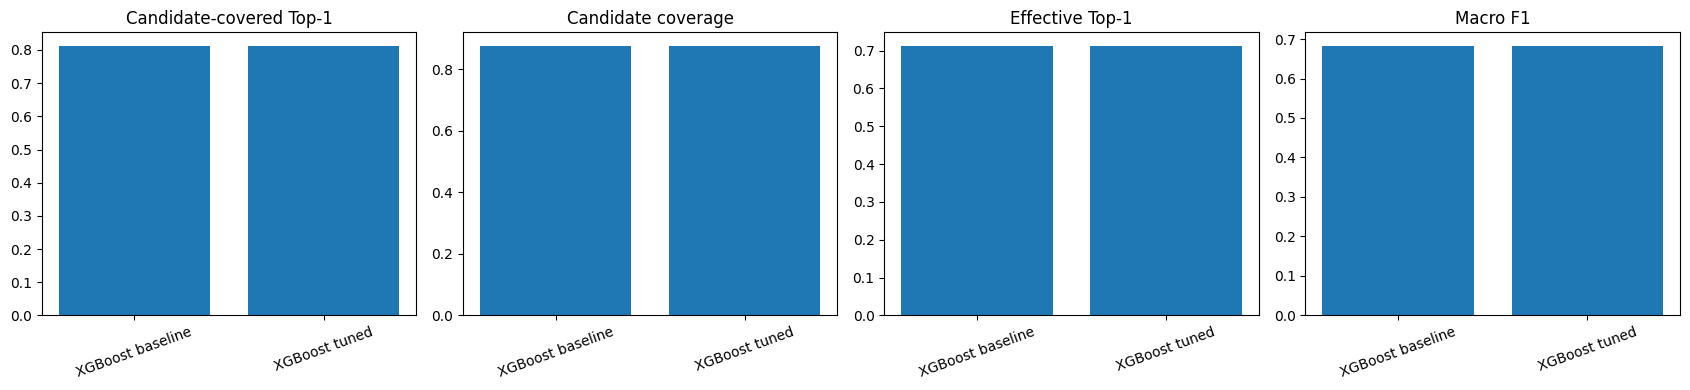

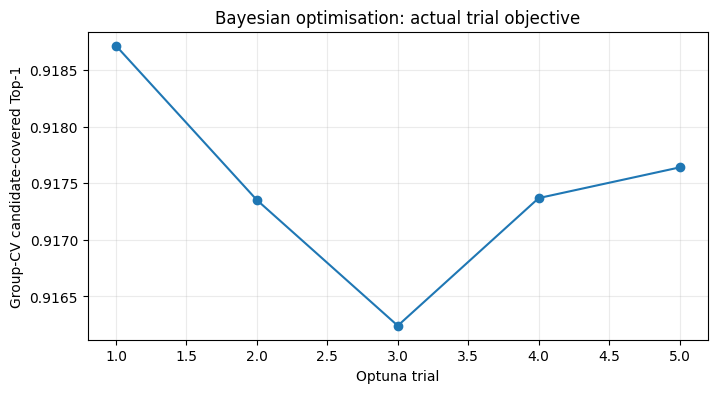

In [18]:
baseline_name=TUNE_FAMILY
baseline_prob=student_probabilities[baseline_name]
baseline_metrics,_=observation_metrics(student_df,baseline_prob)
before_after=pd.DataFrame([
 {"version":baseline_name+" baseline",
  "student_candidate_top1":baseline_metrics["conditional_accuracy"],
  "coverage":baseline_metrics["coverage"],
  "effective_top1":baseline_metrics["effective_accuracy"],
  "macro_f1":baseline_metrics["macro_f1"],
  "candidate_log_loss":log_loss(y_student,baseline_prob,labels=[0,1])},
 {"version":TUNE_FAMILY+" tuned",
  "student_candidate_top1":tuned_metrics["conditional_accuracy"],
  "coverage":tuned_metrics["coverage"],
  "effective_top1":tuned_metrics["effective_accuracy"],
  "macro_f1":tuned_metrics["macro_f1"],
  "candidate_log_loss":log_loss(y_student,tuned_prob,labels=[0,1])}
])
display(before_after)
fig,axes=plt.subplots(1,4,figsize=(17,4))
for ax,col,title in zip(axes,
    ["student_candidate_top1","coverage","effective_top1","macro_f1"],
    ["Candidate-covered Top-1","Candidate coverage","Effective Top-1","Macro F1"]):
    ax.bar(before_after["version"],before_after[col])
    ax.set_title(title); ax.tick_params(axis="x",rotation=20)
plt.tight_layout(); plt.show()
trials_df=study.trials_dataframe()
plt.figure(figsize=(8,4))
plt.plot(np.arange(1,len(trials_df)+1),trials_df["value"],marker="o")
plt.xlabel("Optuna trial"); plt.ylabel("Group-CV candidate-covered Top-1")
plt.title("Bayesian optimisation: actual trial objective")
plt.grid(alpha=.25); plt.show()

## 15. HMM / Viterbi route continuity refinement

This decoder treats candidate road arcs as hidden states. Emission scores come from the classifier probability. Transition scores reward consecutive arcs whose end node equals the next arc's start node; non-connected transitions receive a penalty. It is a practical baseline decoder, not a full shortest-path HMM: a production version can insert shortest-path intermediate arcs for multi-edge gaps and learn transition parameters from training trips.

In [19]:
def viterbi_decode_for_trip(candidate_rows, probs, files, jump_penalty=5.0):
    track,nodes,arcs,route=load_trip(files)
    tmp=candidate_rows[["trip_id","obs_idx","arc_id"]].copy()
    tmp["prob"]=np.asarray(probs)
    groups=[g.sort_values("prob",ascending=False).head(8) for _,g in tmp.groupby("obs_idx")]
    if not groups: return np.array([],dtype=int)
    # Arc topology is local to the trip.
    start_to_arcs=defaultdict(set)
    for aid,(u,v) in enumerate(arcs): start_to_arcs[int(u)].add(aid)
    states=[g.arc_id.astype(int).tolist() for g in groups]
    emissions=[np.log(np.maximum(g.prob.to_numpy(),1e-9)) for g in groups]
    dp=[emissions[0].copy()]; back=[]
    for t in range(1,len(states)):
        prev=states[t-1]; cur=states[t]
        scores=np.full((len(prev),len(cur)),-jump_penalty,dtype=float)
        for i,a in enumerate(prev):
            end_node=int(arcs[a,1])
            for j,b in enumerate(cur):
                if end_node==int(arcs[b,0]): scores[i,j]=0.0
                elif a==b: scores[i,j]=-0.5
        total=dp[-1][:,None]+scores
        ptr=np.argmax(total,axis=0)
        dp.append(emissions[t]+total[ptr,np.arange(len(cur))])
        back.append(ptr)
    path=[int(np.argmax(dp[-1]))]
    for ptr in reversed(back): path.append(int(ptr[path[-1]]))
    path=path[::-1]
    return np.array([states[t][path[t]] for t in range(len(path))])

def continuity_rate(path, arcs):
    if len(path)<2: return np.nan
    valid=[(a,b) for a,b in zip(path[:-1],path[1:]) if 0<=a<len(arcs) and 0<=b<len(arcs)]
    if not valid: return np.nan
    return float(np.mean([arcs[a,1]==arcs[b,0] for a,b in valid]))

# Classifier-only vs HMM continuity on student trips
hmm_rows=[]
for tid in sorted(student_df.trip_id.unique()):
    sub=student_df[student_df.trip_id==tid].copy()
    idx=sub.index
    p=tuned_model.predict_proba(X_student.loc[idx])[:,1]
    ranked=rank_predictions(sub,p).sort_values("obs_idx")
    files=TRIPS[("student_test",tid)]
    _,nodes,arcs,_=load_trip(files)
    classifier_path=ranked.arc_id.to_numpy(dtype=int)
    hmm_path=viterbi_decode_for_trip(sub,p,files)
    hmm_rows.append({"trip_id":tid,
        "classifier_continuity":continuity_rate(classifier_path,arcs),
        "hmm_continuity":continuity_rate(hmm_path,arcs),
        "observations":len(hmm_path)})
hmm_results=pd.DataFrame(hmm_rows)
display(hmm_results)
print("Mean classifier continuity:",hmm_results.classifier_continuity.mean())
print("Mean HMM continuity:",hmm_results.hmm_continuity.mean())

,trip_id,classifier_continuity,hmm_continuity,observations
0,00000000,0.114309,0.189848,2503
1,00000007,0.203252,0.243902,1354
2,00000009,0.357824,0.499046,1049
3,00000040,0.225117,0.339011,2995
4,00000052,0.249042,0.306513,262
5,00000056,0.288602,0.379075,3958
6,00000065,0.238592,0.398957,768
7,00000076,0.290236,0.482155,1486
8,00000077,0.446803,0.636061,3911
9,00000091,0.268041,0.381443,874


Mean classifier continuity: 0.2681818448804711
Mean HMM continuity: 0.3856012722348559


## 16. Inspect one trip visually with Folium

The map shows GPS observations and the classifier/HMM road-segment predictions for a selected student-test trip. Folium tiles require internet access in the browser. The HTML map is saved as an artifact.

In [20]:
import folium
from IPython.display import display, IFrame
selected_trip=sorted(student_df.trip_id.unique())[0]
fs=TRIPS[("student_test",selected_trip)]
track,nodes,arcs,route=load_trip_cleaned(fs,selected_trip,"student_test")
sub=student_df[student_df.trip_id==selected_trip].copy()
p=tuned_model.predict_proba(X_student.loc[sub.index])[:,1]
ranked=rank_predictions(sub,p).sort_values("obs_idx")
pred_ids=ranked.arc_id.to_numpy(dtype=int)
center=[float(np.mean(track[:,1])),float(np.mean(track[:,0]))]
m=folium.Map(location=center,zoom_start=14,control_scale=True)
gps=[(float(lat),float(lon)) for lon,lat,_ in track]
folium.PolyLine(gps,color="blue",weight=3,opacity=.8,tooltip="GPS trajectory").add_to(m)
def arc_coords(ids):
    out=[]
    for aid in ids:
        if 0<=int(aid)<len(arcs):
            u,v=arcs[int(aid)]
            out.append([(float(nodes[u,1]),float(nodes[u,0])),(float(nodes[v,1]),float(nodes[v,0]))])
    return out
for coords in arc_coords(pred_ids):
    folium.PolyLine(coords,color="red",weight=3,opacity=.7,tooltip="Predicted arc").add_to(m)
route_valid=route[(route>=0)&(route<len(arcs))]
for coords in arc_coords(route_valid):
    folium.PolyLine(coords,color="green",weight=2,opacity=.55,tooltip="Reference route").add_to(m)
folium.LayerControl().add_to(m)
MAP_PATH=str(Path.cwd() / "pathsnap_sample_map.html")
m.save(MAP_PATH)
display(m)
print("Saved:",MAP_PATH)

Saved: /content/pathsnap_sample_map.html


## 17. Save models, results, configurations and notebook outputs

The output folder contains the tuned model, preprocessing/feature configuration, model comparison CSVs, diagnostics, and a sample Folium map. The ZIP created at the end can be downloaded and added to your GitHub repository (do not include evaluator ground truth or secrets).

In [21]:
import joblib
OUT=Path.cwd()/"pathsnap_outputs"
OUT.mkdir(exist_ok=True)
joblib.dump(tuned_model,OUT/"pathsnap_best_model.joblib")
joblib.dump({"features":FEATURES,"candidate_k":K_CANDIDATES,
             "tune_family":TUNE_FAMILY,"best_params":study.best_params,
             "label_method":"nearest supplied route arc by point-to-segment distance",
             "seed":SEED,"cleaning_rules":{"remove_nonfinite":True,"remove_invalid_lon_lat":True,"remove_consecutive_exact_duplicates":True,"deduplicate_timestamps_keep_first":True,"preserve_long_gaps":True,"max_speed_feature_mps":MAX_REASONABLE_SPEED_MPS}},OUT/"pathsnap_config.joblib")
comparison.to_csv(OUT/"model_comparison.csv",index=False)
cleaning_audit_df.to_csv(OUT/"gps_cleaning_audit.csv",index=False)
cleaning_events_df.to_csv(OUT/"gps_cleaning_correction_log.csv",index=False)
before_after.to_csv(OUT/"bayesian_before_after.csv",index=False)
with open(OUT/"boosting_training_histories.json","w") as f: json.dump(history_records,f)
cv_results.to_csv(OUT/"cross_validation_results.csv",index=False)
diagnostics_df.to_csv(OUT/"candidate_diagnostics.csv",index=False)
hmm_results.to_csv(OUT/"hmm_continuity_comparison.csv",index=False)
study.trials_dataframe().to_csv(OUT/"optuna_trials.csv",index=False)
if Path(MAP_PATH).exists(): shutil.copy(MAP_PATH,OUT/"sample_trip_map.html")
if "EDA_MAP_PATH" in globals() and Path(EDA_MAP_PATH).exists(): shutil.copy(EDA_MAP_PATH,OUT/"eda_training_trip_map.html")
print("Saved artifacts:")
for p in OUT.iterdir(): print(p.name, f"{p.stat().st_size/1024:.1f} KB")
archive_path=shutil.make_archive(str(Path.cwd()/"pathsnap_training_artifacts"),"zip",OUT)
print("Artifact archive:",archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Not running in Google Colab; download the archive from the current working directory.")

Saved artifacts:
eda_training_trip_map.html 412.6 KB
bayesian_before_after.csv 0.3 KB
optuna_trials.csv 1.1 KB
sample_trip_map.html 1985.3 KB
pathsnap_config.joblib 0.6 KB
gps_cleaning_audit.csv 4.3 KB
cross_validation_results.csv 0.6 KB
model_comparison.csv 1.2 KB
candidate_diagnostics.csv 6.3 KB
hmm_continuity_comparison.csv 0.6 KB
gps_cleaning_correction_log.csv 6.0 KB
pathsnap_best_model.joblib 4153.9 KB
boosting_training_histories.json 14.6 KB
Artifact archive: /content/pathsnap_training_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17A. API / frontend integration handoff

This notebook exports the trained estimator, exact feature list, candidate-generation settings, cleaning rules, and evaluation artifacts for the backend. The API and frontend source code were not part of the uploaded dataset/notebook files, so this notebook cannot honestly claim to implement or test your friend's API or UI. After the backend/frontend repository is supplied, validate its endpoint schema against the exported model contract and test the evaluator trips end-to-end.

In [22]:
# Display the serving contract that the backend must follow.
serving_contract = {
    "model_file":"pathsnap_best_model.joblib",
    "config_file":"pathsnap_config.joblib",
    "model_family":TUNE_FAMILY,
    "feature_columns":FEATURES,
    "candidate_count":K_CANDIDATES,
    "coordinate_order":"longitude, latitude",
    "gps_cleaning":"same conservative cleaning rules exported in pathsnap_config.joblib",
    "prediction_output":"one ranked road-arc candidate per GPS observation",
    "ground_truth_policy":"reference .route is evaluation-only and must not be required by inference API"
}
display(pd.DataFrame([{"key":k,"value":str(v)} for k,v in serving_contract.items()]))
print("Backend handoff files are created in:",OUT if "OUT" in globals() else "pathsnap_outputs (after artifact-save cell)")

,key,value
0,model_file,pathsnap_best_model.joblib
1,config_file,pathsnap_config.joblib
2,model_family,XGBoost
3,feature_columns,"['point_seg_dist_m', 'midpoint_dist_m', 'segme..."
4,candidate_count,6
5,coordinate_order,"longitude, latitude"
6,gps_cleaning,same conservative cleaning rules exported in p...
7,prediction_output,one ranked road-arc candidate per GPS observation
8,ground_truth_policy,reference .route is evaluation-only and must n...


Backend handoff files are created in: /content/pathsnap_outputs


## 18. Final checklist and interpretation

Before using results in the technical report:

1. Confirm the partition counts are 80 training and 10 student-testing trips.
2. Review candidate hit rate and GPS-to-reference snap-distance diagnostics.
3. Check that the cross-validation folds are grouped by trip.
4. Compare CV Macro F1 and student-test Top-1/Macro F1; do not select by training score.
5. Record actual tuning trials and the tuned-vs-untuned comparison.
6. Compare classifier-only and HMM route continuity, and inspect the Folium map.
7. Clearly state the observation-label alignment approximation in the report.

**Do not claim 90% unless the notebook actually measures it.** If performance is lower, the next improvement should be candidate generation, route-to-observation alignment, and transition modelling—not fabricated metrics or evaluator-label leakage.

9. Include `gps_cleaning_audit.csv`, `gps_cleaning_correction_log.csv`, model metrics, Optuna trials, Folium maps, and the model/config files in the submission. Validate API/UI only after connecting the supplied backend/frontend source.